# 01 - Dataset analysis (WP1) and fixed split (WP2)

> **Dataset licence.** ViGoEmotions is for non-commercial research/education only and must not be redistributed. Keep `data/` and `results/private/` out of any public repository; the tables in `results/tables/` contain only aggregates, ids and labels.

In [1]:
# ---- Setup: works both locally and on Google Colab --------------------------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # EDIT: folder on your Drive that contains src/, configs/, resources/ and data/{train,val,test}.csv
    PROJECT_DIR = "/content/drive/MyDrive/vigoemotions_midterm"
    os.chdir(PROJECT_DIR)
    subprocess.run("pip -q install -r requirements-colab.txt", shell=True, check=True)
    # Java is needed by VnCoreNLP (PhoBERT word segmentation); falls back to pyvi otherwise
    if subprocess.run("java -version", shell=True, capture_output=True).returncode != 0:
        subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
os.environ["PYTHONPATH"] = os.path.abspath("src") + os.pathsep + os.environ.get("PYTHONPATH", "")
print("project dir:", os.getcwd())

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
T = lambda name: pd.read_csv(f"results/tables/{name}")          # noqa: E731
F = lambda name, w=900: display(Image(f"results/figures/{name}", width=w))  # noqa: E731

project dir: /Users/tam/Documents/projects/ATI/midterm


In [2]:
!python -m vigo eda
!python -m vigo split --make iterative

                            item     value
                  total comments     20664
                  train comments     16531
                    val comments      2066
                   test comments      2067
  labels (27 emotions + neutral)        28
     mean labels per comment |Y|     1.909
                   label density    0.0682
             distinct label sets      1485
     most frequent label (train) amusement
            rarest label (train)    relief
 imbalance ratio max/min (train)      4.52
median whitespace tokens (train)      11.0

cardinality:
 split     n  mean  median  max  density  pct_|Y|=1  pct_|Y|=2  pct_|Y|=3  pct_|Y|=4  pct_|Y|=5  neutral_only_pct
train 16531 1.908     2.0    5    0.068      32.85      46.62      17.63       2.65       0.25              3.45
  val  2066 1.916     2.0    5    0.068      32.87      45.69      18.78       2.32       0.34              3.63
 test  2067 1.907     2.0    5    0.068      33.62      45.77      17.42       2.66    

                split_protocol  train_n  train_mad_rate  train_LD  train_min_pos  val_n  val_mad_rate  val_LD  val_min_pos  test_n  test_mad_rate  test_LD  test_min_pos  LD_mean
           official (released)    16531         0.00066   0.00076            635   2066       0.00487 0.00573           58    2067        0.00354  0.00415            60  0.00355
              random (seed 42)    16531         0.00106   0.00127            592   2066       0.00405 0.00469           73    2067        0.00604  0.00729            88  0.00441
iterative stratified (seed 42)    16533         0.00002   0.00002            602   2047       0.00055 0.00067           75    2084        0.00045  0.00055            76  0.00041


wrote /Users/tam/Documents/projects/ATI/midterm/splits/official/{train,val,test}_ids.txt
wrote /Users/tam/Documents/projects/ATI/midterm/splits/iterative/{train,val,test}_ids.txt
data dir: /Users/tam/Documents/projects/ATI/midterm/data


## A. Sample count and the complete label inventory

In [3]:
display(T("dataset_summary.csv"))
display(T("label_inventory.csv"))

,item,value
0,total comments,20664
1,train comments,16531
2,val comments,2066
3,test comments,2067
4,labels (27 emotions + neutral),28
5,mean labels per comment |Y|,1.909
6,label density,0.0682
7,distinct label sets,1485
8,most frequent label (train),amusement
9,rarest label (train),relief


,index,label,train_count,train_pct,val_count,val_pct,test_count,test_pct,all_count,tier,train_rank
0,0,amusement,2868,17.35,327,15.83,374,18.09,3569,head,1
1,1,excitement,824,4.98,91,4.40,98,4.74,1013,mid,16
2,2,joy,1614,9.76,168,8.13,204,9.87,1986,head,4
3,3,love,1175,7.11,148,7.16,143,6.92,1466,head,8
4,4,desire,762,4.61,102,4.94,80,3.87,944,tail,20
5,5,optimism,1046,6.33,122,5.91,142,6.87,1310,mid,10
6,6,caring,1062,6.42,131,6.34,150,7.26,1343,head,9
7,7,pride,774,4.68,87,4.21,86,4.16,947,mid,18
8,8,admiration,883,5.34,107,5.18,101,4.89,1091,mid,14
9,9,gratitude,765,4.63,96,4.65,108,5.22,969,mid,19


## B. Label frequency and head / mid / tail tiers
Rule (fixed before any model was evaluated): rank labels by **training** positive count; tertiles give
9 head / 10 mid / 9 tail labels. The imbalance is mild (max/min = 4.5x) compared with GoEmotions.

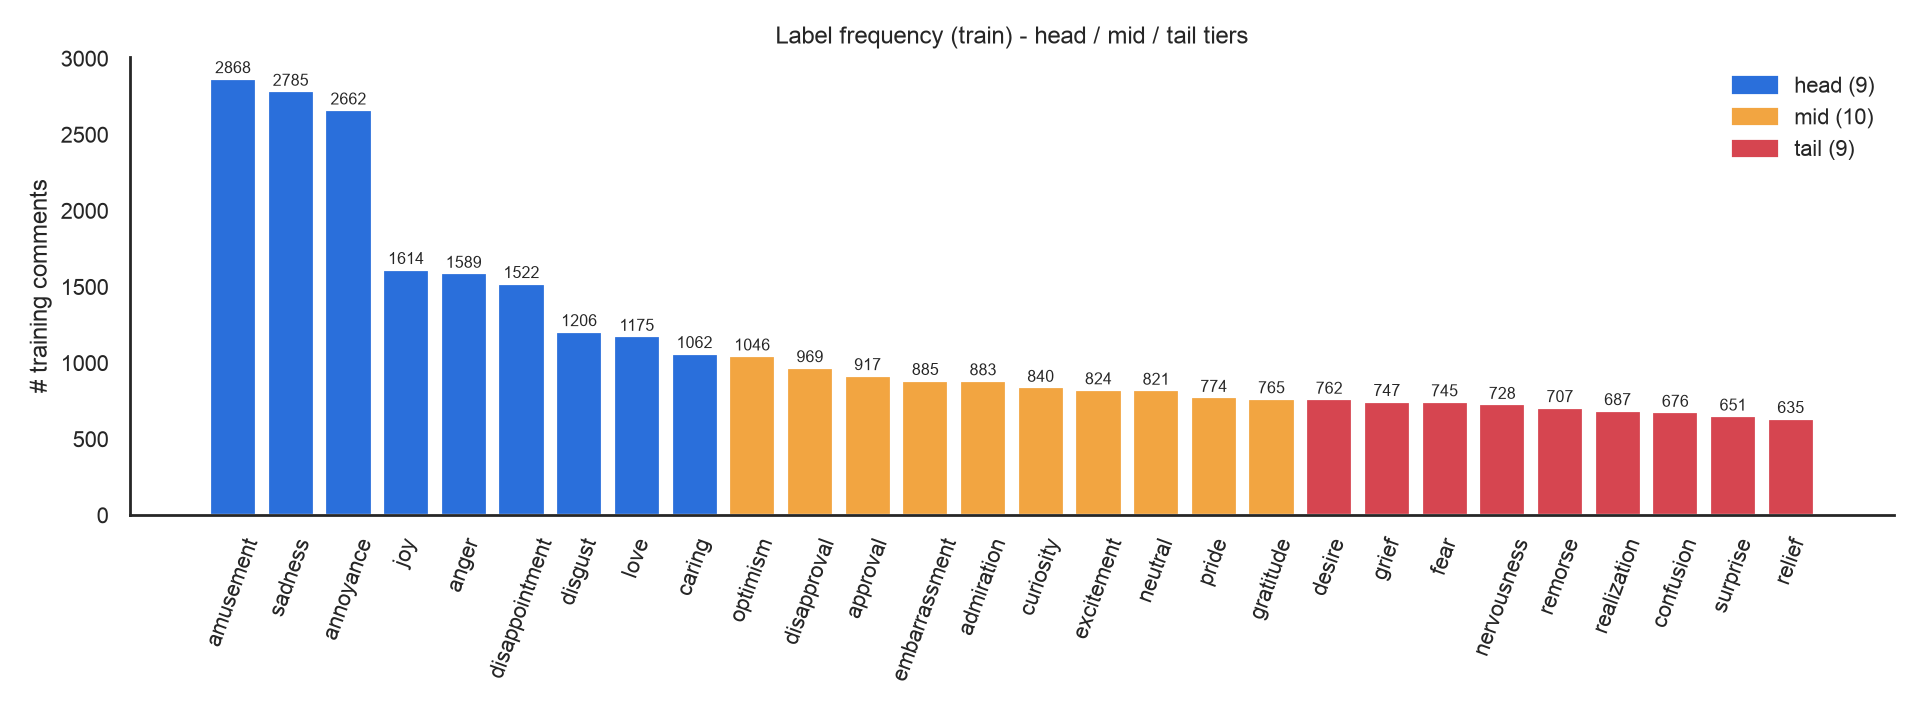

,tier,n_labels,min_count,max_count,labels,rule
0,head,9,1062,2868,"amusement, sadness, annoyance, joy, anger, dis...",tertiles of training positive counts (9 head /...
1,mid,10,765,1046,"optimism, disapproval, approval, embarrassment...",tertiles of training positive counts (9 head /...
2,tail,9,635,762,"desire, grief, fear, nervousness, remorse, rea...",tertiles of training positive counts (9 head /...


In [4]:
F("label_frequency.png")
display(T("label_tiers.csv"))

## C. Label cardinality |Y|

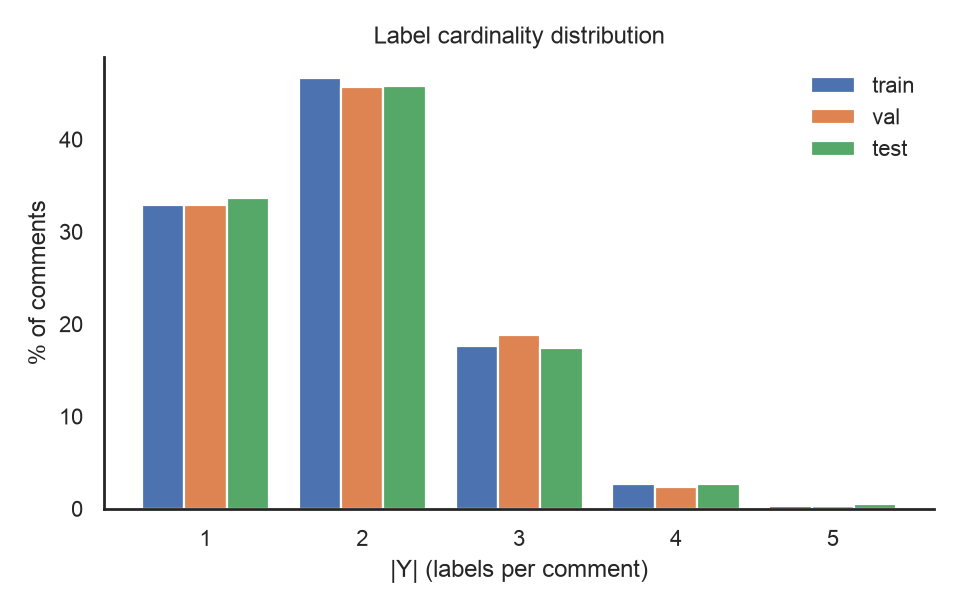

,split,n,mean,median,max,density,pct_|Y|=1,pct_|Y|=2,pct_|Y|=3,pct_|Y|=4,pct_|Y|=5,neutral_only_pct
0,train,16531,1.908233,2.0,5,0.068151,32.85,46.62,17.63,2.65,0.25,3.45
1,val,2066,1.915779,2.0,5,0.068421,32.87,45.69,18.78,2.32,0.34,3.63
2,test,2067,1.907112,2.0,5,0.068111,33.62,45.77,17.42,2.66,0.53,3.87


In [5]:
F("cardinality_distribution.png", 600)
display(T("cardinality_summary.csv"))

## D. Co-occurrence and pairwise correlation (training labels only)

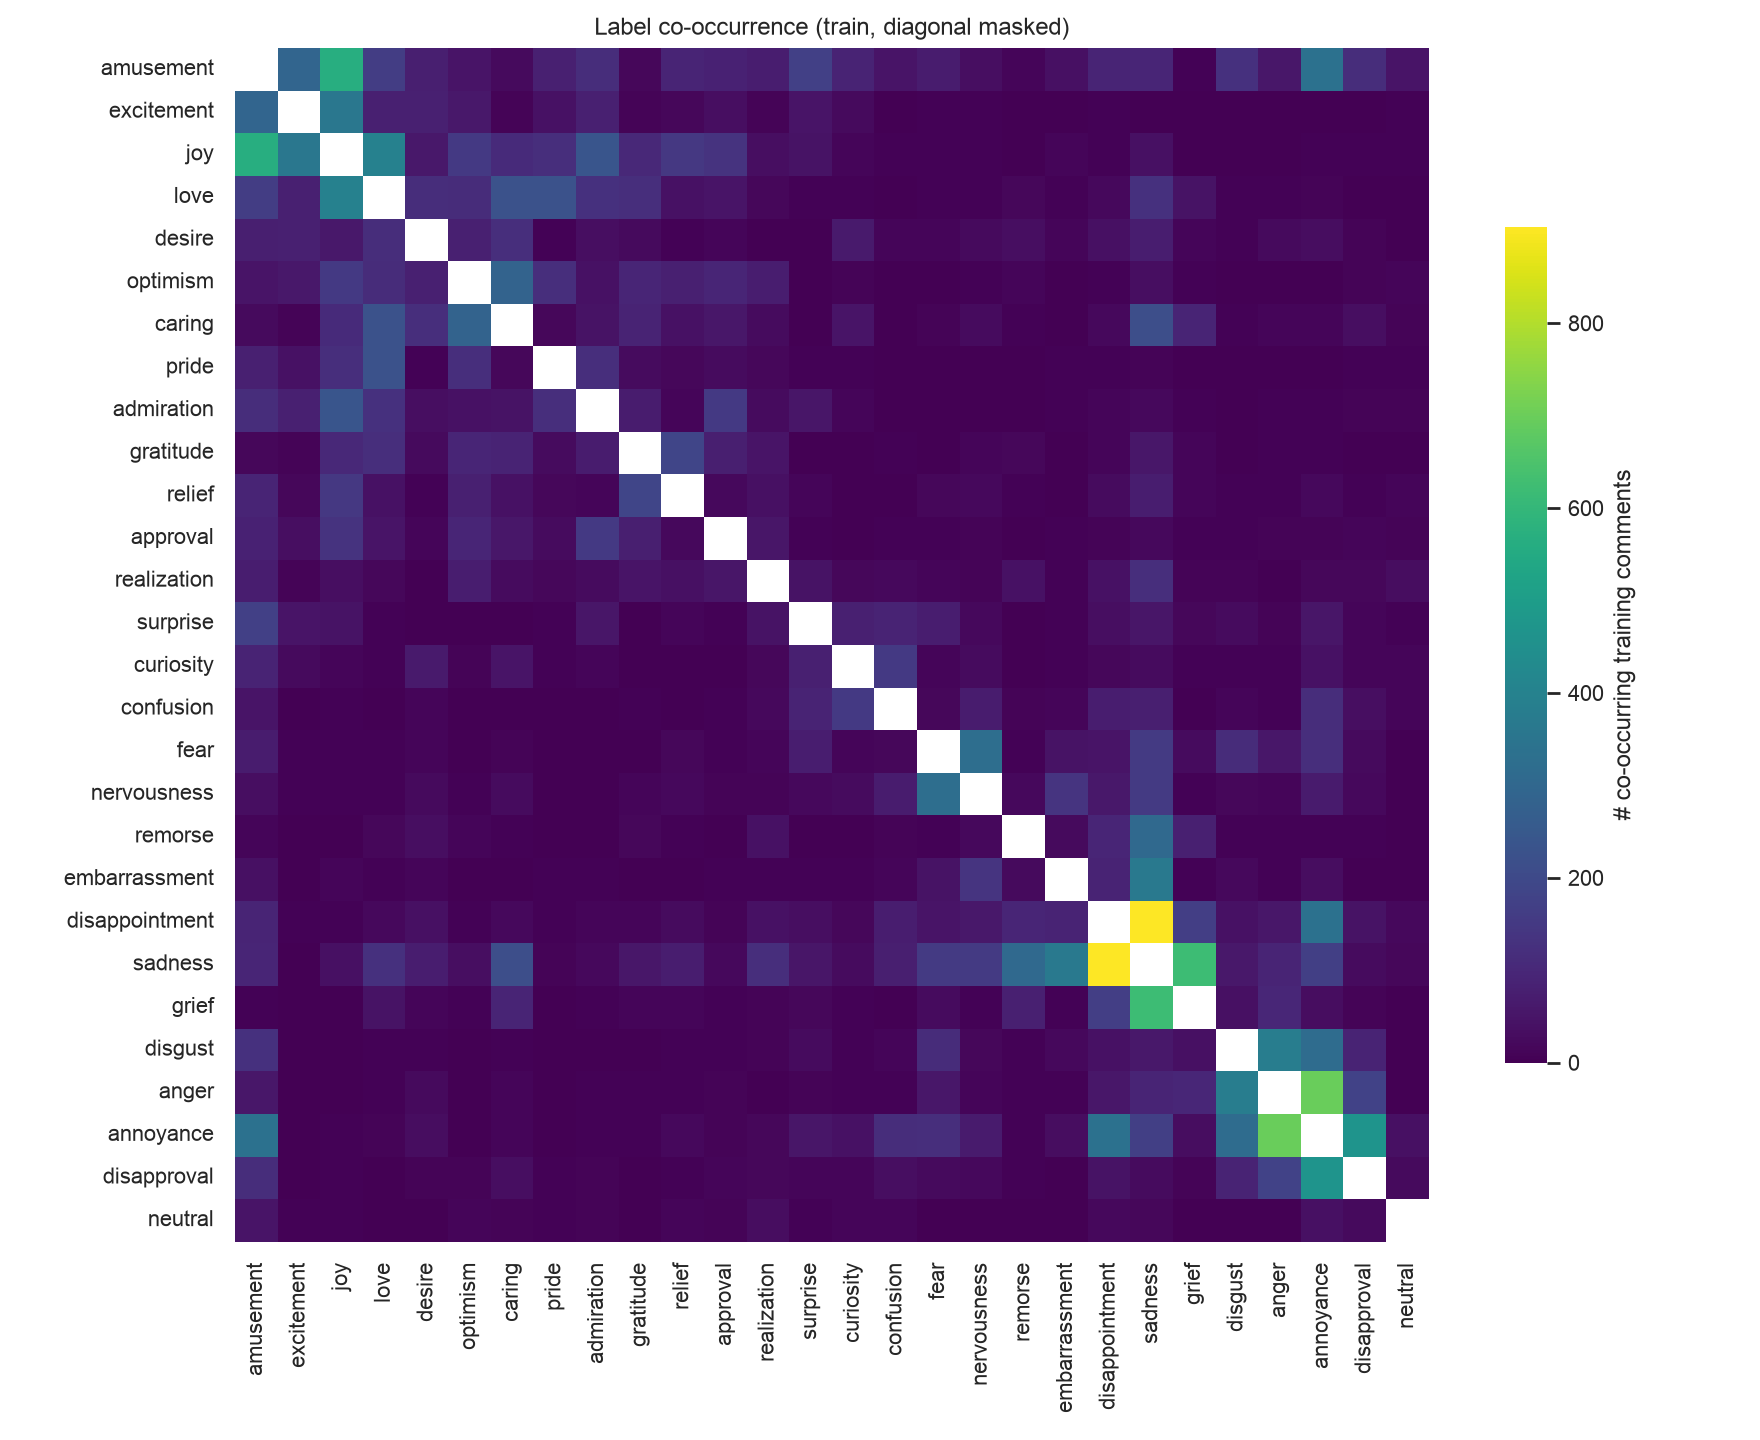

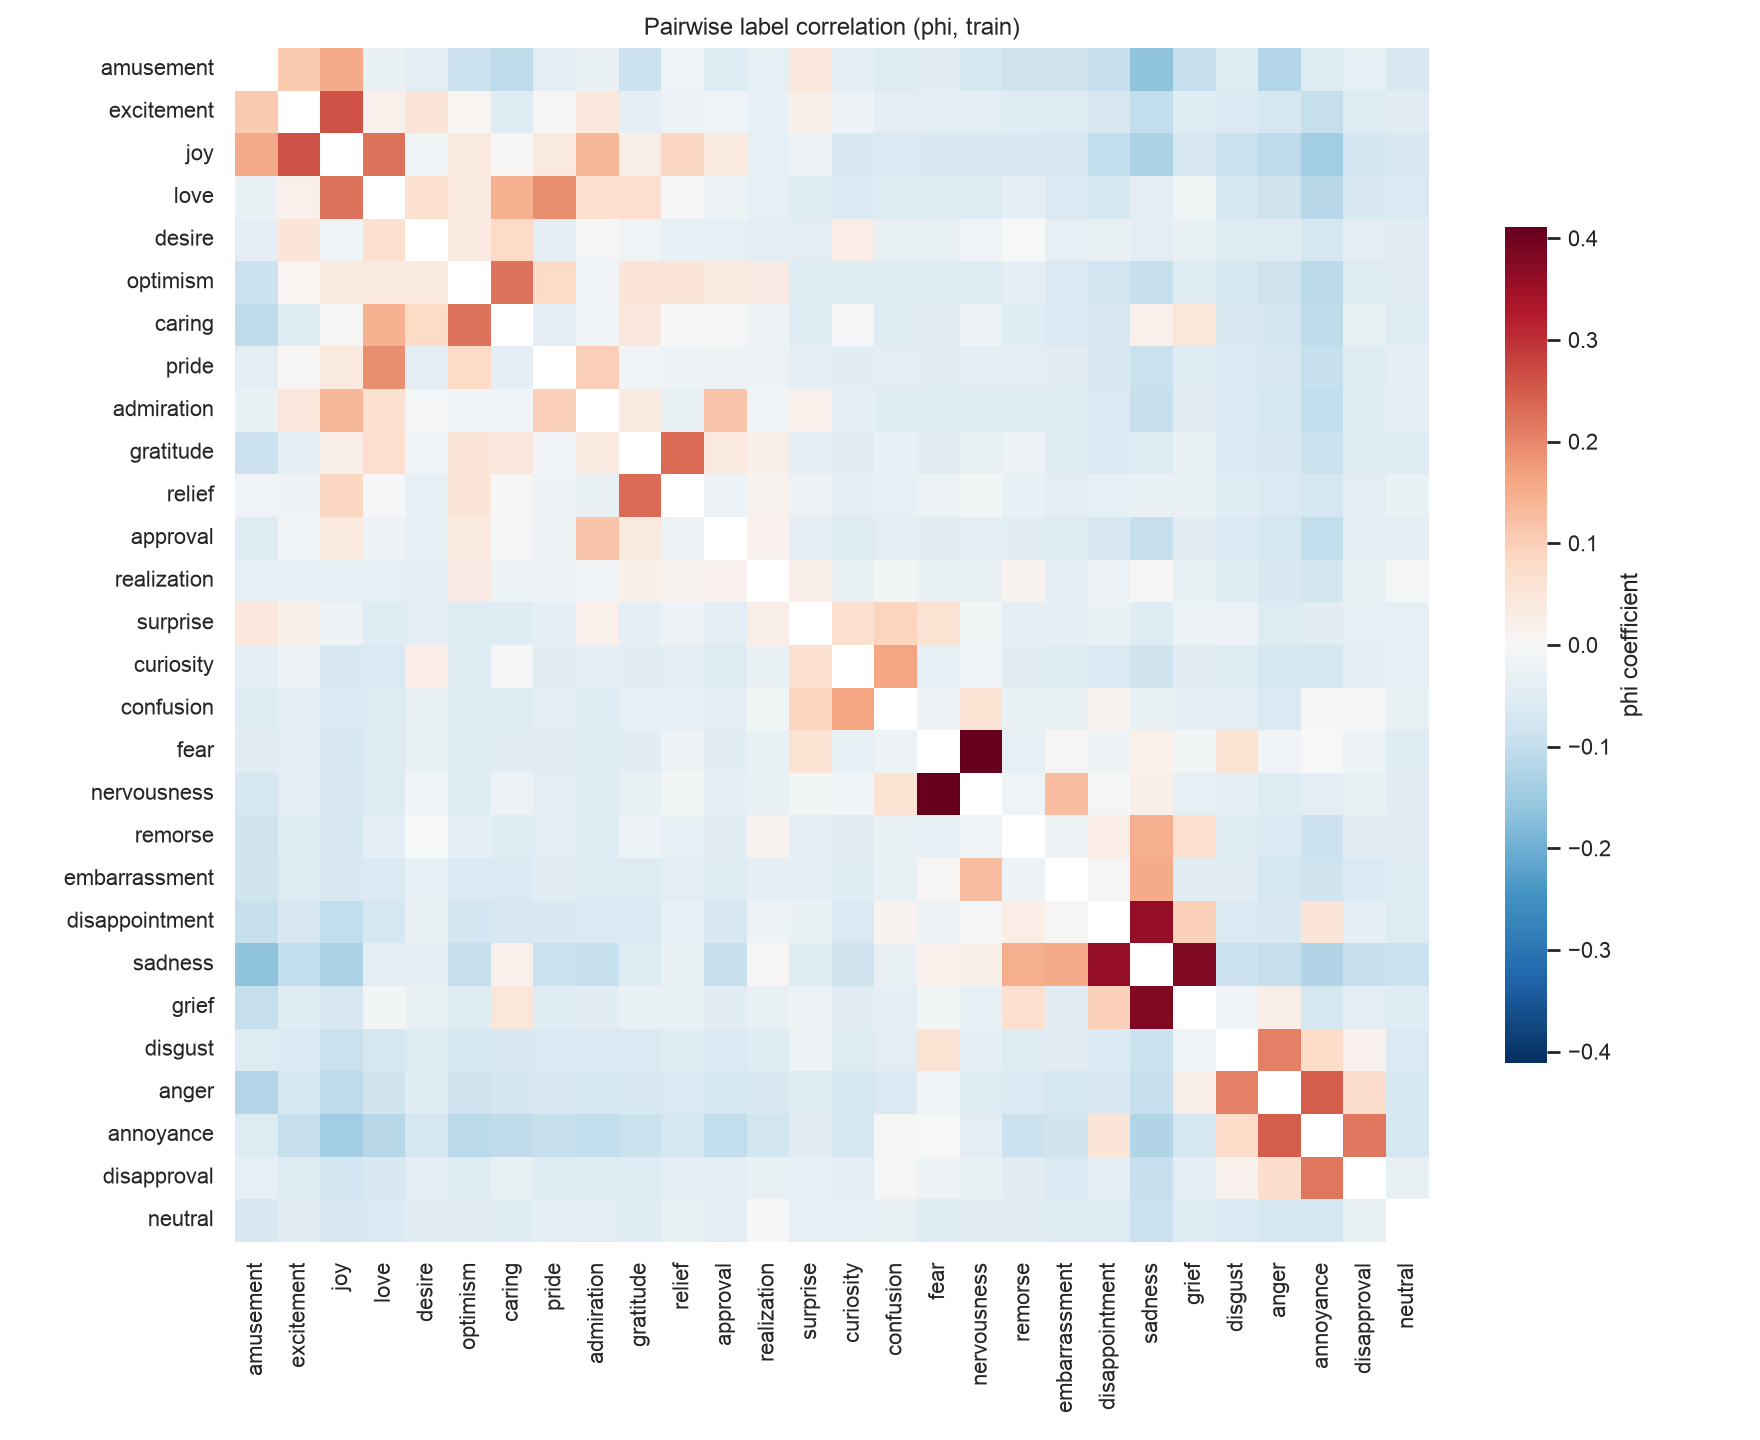

,label_a,label_b,count,pct_of_train,P(b|a),P(a|b),phi,pmi
0,disappointment,sadness,904,5.47,0.594,0.325,0.362,1.818
1,anger,annoyance,699,4.23,0.440,0.263,0.247,1.450
2,sadness,grief,620,3.75,0.223,0.830,0.384,2.301
3,amusement,joy,568,3.44,0.198,0.352,0.155,1.020
4,annoyance,disapproval,469,2.84,0.176,0.484,0.219,1.588
5,joy,love,395,2.39,0.245,0.336,0.222,1.784
6,disgust,anger,379,2.29,0.314,0.239,0.208,1.709
7,embarrassment,sadness,366,2.21,0.414,0.131,0.156,1.296
8,excitement,joy,359,2.17,0.436,0.222,0.261,2.158
9,disappointment,annoyance,336,2.03,0.221,0.126,0.052,0.455


In [6]:
F("cooccurrence.png", 750)
F("correlation.png", 750)
display(T("top_pairs.csv"))

## E. Text length (whitespace tokens and characters)

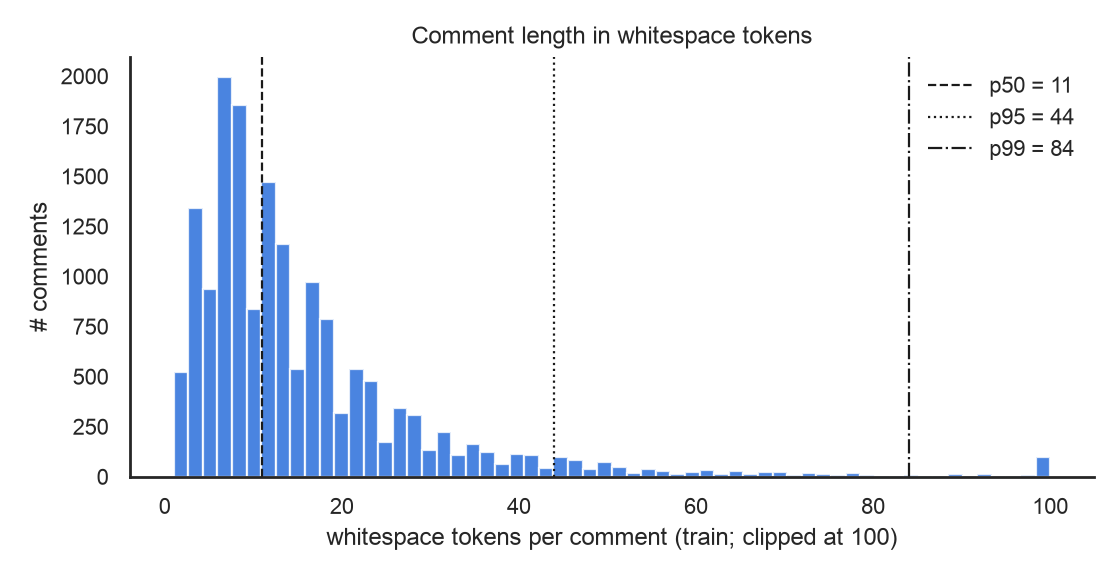

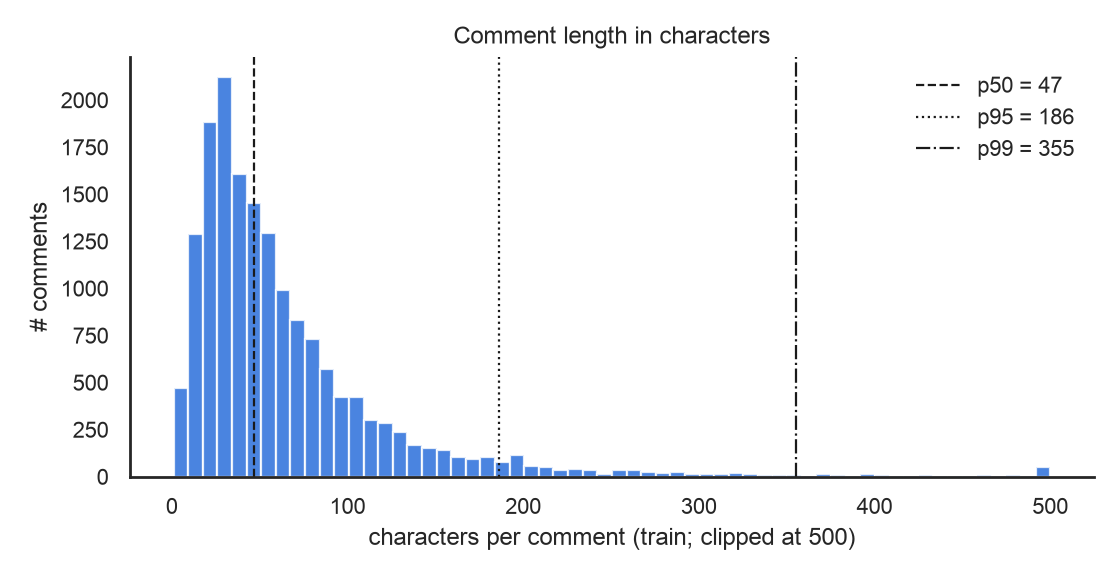

,split,unit,min,p25,median,mean,p90,p95,p99,max
0,train,whitespace_tokens,1,7.0,11.0,16.05,32.0,44.00,84.00,214
1,train,characters,1,28.0,47.0,66.51,133.0,186.00,355.00,906
2,val,whitespace_tokens,1,7.0,12.0,16.06,32.0,44.00,88.00,143
3,val,characters,1,27.0,47.0,66.54,130.5,187.75,363.40,641
4,test,whitespace_tokens,1,7.0,11.0,16.82,35.0,47.00,90.68,171
5,test,characters,1,28.0,47.0,69.58,145.0,194.00,380.04,694


In [7]:
F("token_length.png", 650)
F("char_length.png", 650)
display(T("text_length_stats.csv"))

## F. Informal Vietnamese: slang, teencode, emoji, non-standard syntax
Aggregate statistics only (no raw comments are stored in `results/tables`).

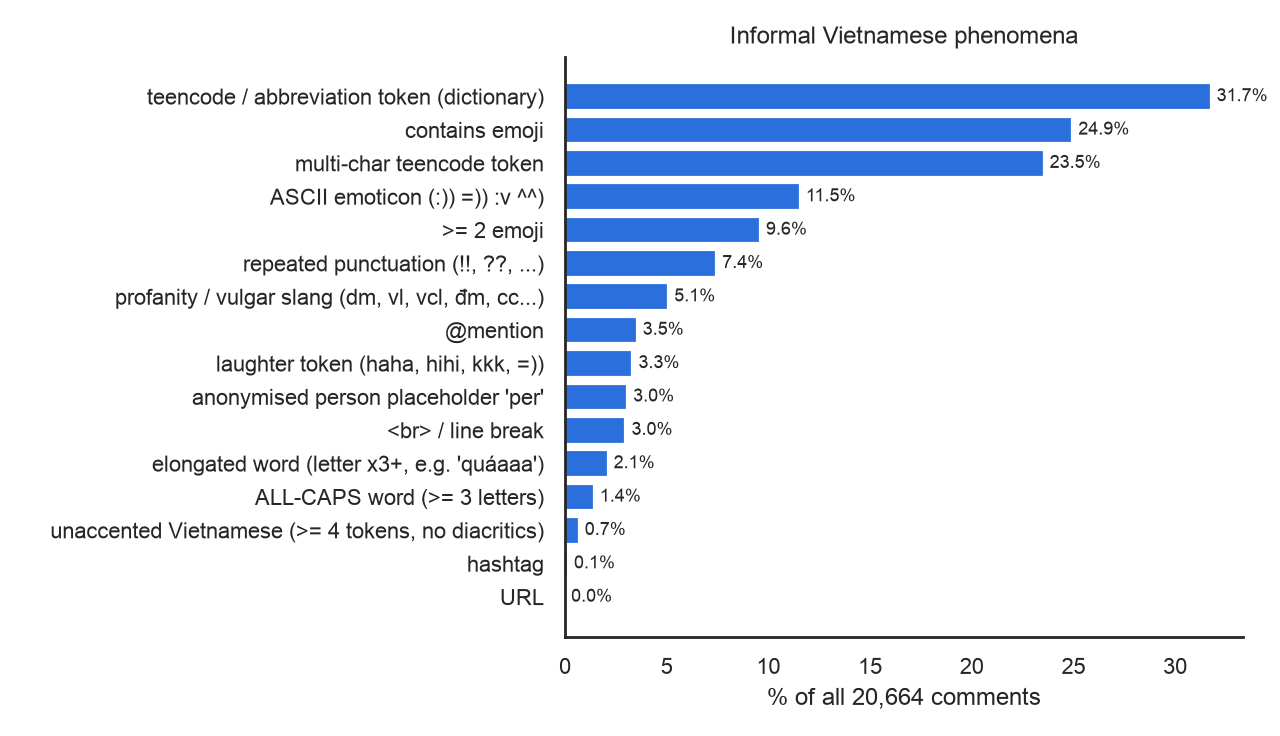

,phenomenon,n_comments,pct
0,contains emoji,5153,24.94
1,>= 2 emoji,1980,9.58
2,ASCII emoticon (:)) =)) :v ^^),2385,11.54
3,teencode / abbreviation token (dictionary),6559,31.74
4,multi-char teencode token,4862,23.53
5,"elongated word (letter x3+, e.g. 'quáaaa')",432,2.09
6,"repeated punctuation (!!, ??, ...)",1535,7.43
7,"laughter token (haha, hihi, kkk, =))",684,3.31
8,@mention,727,3.52
9,URL,0,0.00


,token,normalised,count
0,ko,không,1618
1,t,tao,1096
2,k,không,965
3,e,em,695
4,đc,được,598
5,a,anh,487
6,ng,người,404
7,v,vậy,299
8,r,rồi,290
9,c,chị,259


,emoji,name,count
0,😂,face_with_tears_of_joy,1051
1,🤣,rolling_on_the_floor_laughing,661
2,❤,red_heart,620
3,😭,loudly_crying_face,493
4,🇻🇳,Vietnam,485
5,🥰,smiling_face_with_hearts,457
6,👍,thumbs_up,288
7,😌,relieved_face,282
8,🙏,folded_hands,276
9,🥺,pleading_face,263


,label,pct_with_emoji
0,love,48.8
1,pride,44.4
2,amusement,40.8
3,embarrassment,38.4
4,relief,38.3
5,joy,37.1
6,grief,35.1
7,remorse,33.5
8,sadness,31.7
9,excitement,30.9


,0,train,val,test,total,pct
0,"Facebook (numeric id, incl. UIT-VSMEC)",10741,1339,1364,13444,65.06
1,TikTok,3609,463,436,4508,21.82
2,YouTube,1563,199,198,1960,9.49
3,X (Twitter),430,48,46,524,2.54
4,Reddit,140,13,14,167,0.81
5,Threads,48,4,9,61,0.30


In [8]:
F("informal_text_audit.png", 750)
display(T("informal_text_audit.csv"))
display(T("teencode_top.csv").head(25))
display(T("emoji_top.csv").head(25))
display(T("emoji_rate_by_label.csv"))
display(T("source_distribution.csv"))

### Preprocessing illustration (synthetic sentences, not dataset comments)

In [9]:
from vigo.data.preprocessing import TextNormalizer, segment_texts
examples = ["Hôm nay vui quáaaa =))))) ko ngờ luôn 😂😂😂", "@BanA sao mik thấy bùn ghê :(( hòa bình thủy",
            "đẹppppp zai vcl 🥰🥰", "Bài học:<br>1: kkkkk"]
for mode in ("keep", "text"):
    n = TextNormalizer({"emoji": mode})
    print(f"--- emoji={mode}")
    for e in examples:
        out = n(e)
        print(f"{e!r:55} -> {out!r}\n{'':55}    seg: {segment_texts([out])[0]!r}")

--- emoji=keep


2026-09-29 14:35:45 INFO  WordSegmenter:24 - Loading Word Segmentation model
'Hôm nay vui quáaaa =))))) ko ngờ luôn 😂😂😂'             -> 'hôm nay vui quá =)) không ngờ luôn 😂'
                                                           seg: 'hôm_nay vui quá =)) không ngờ luôn 😂'
'@BanA sao mik thấy bùn ghê :(( hòa bình thủy'          -> '@user sao mình thấy buồn ghê :(( hoà bình thuỷ'
                                                           seg: '@user sao mình thấy buồn ghê :(( hoà_bình thuỷ'
'đẹppppp zai vcl 🥰🥰'                                    -> 'đẹp trai vãi cả lồn 🥰'
                                                           seg: 'đẹp_trai vãi cả lồn 🥰'
'Bài học:<br>1: kkkkk'                                  -> 'bài học : 1 : haha'
                                                           seg: 'bài_học : 1 : haha'
--- emoji=text
'Hôm nay vui quáaaa =))))) ko ngờ luôn 😂😂😂'             -> 'hôm nay vui quá cười rũ rượi không ngờ luôn cười ra nước mắt'
                            

## G. Stratified multi-label split protocol

We keep the **official 80/10/10 split** released with the dataset (comparable with the paper) and audit
its stratification against a random split and an iterative multi-label stratified split (Sechidis et al., 2011)
generated with the same seed. Lower LD / MAD = better label-distribution preservation.

In [10]:
display(T("split_quality_audit.csv"))
display(T("split_label_coverage.csv"))
display(T("text_style_subsets.csv"))

,split_protocol,train_n,train_mad_rate,train_LD,train_min_pos,val_n,val_mad_rate,val_LD,val_min_pos,test_n,test_mad_rate,test_LD,test_min_pos,LD_mean
0,official (released),16531,0.000660,0.000760,635,2066,0.004870,0.005733,58,2067,0.003541,0.004148,60,0.003547
1,random (seed 42),16531,0.001057,0.001265,592,2066,0.004054,0.004685,73,2067,0.006039,0.007285,88,0.004412
2,iterative stratified (seed 42),16533,0.000017,0.000019,602,2047,0.000550,0.000673,75,2084,0.000449,0.000552,76,0.000415


,label,train_count,train_pct,val_count,val_pct,test_count,test_pct
0,amusement,2868,17.35,327,15.83,374,18.09
1,excitement,824,4.98,91,4.40,98,4.74
2,joy,1614,9.76,168,8.13,204,9.87
3,love,1175,7.11,148,7.16,143,6.92
4,desire,762,4.61,102,4.94,80,3.87
5,optimism,1046,6.33,122,5.91,142,6.87
6,caring,1062,6.42,131,6.34,150,7.26
7,pride,774,4.68,87,4.21,86,4.16
8,admiration,883,5.34,107,5.18,101,4.89
9,gratitude,765,4.63,96,4.65,108,5.22


,Unnamed: 0,Unnamed: 1,n,n.1,n.2,pct,pct.1,pct.2
0,split,NaN,test,train,val,test,train,val
1,subset,rule,NaN,NaN,NaN,NaN,NaN,NaN
2,emoji,>= 1 emoji,536.0,4109.0,508.0,25.93,24.86,24.59
3,emoji_heavy,>= 2 emoji characters,180.0,1600.0,200.0,8.71,9.68,9.68
4,emoticon,>= 1 ASCII emoticon,236.0,1896.0,253.0,11.42,11.47,12.25
5,long,>= 30 whitespace tokens,283.0,1951.0,244.0,13.69,11.8,11.81
6,plain,"not short, no emoji/emoticon/teencode",793.0,6521.0,804.0,38.36,39.45,38.92
7,short,<= 5 whitespace tokens,337.0,2805.0,343.0,16.3,16.97,16.6
8,teencode,>= 1 multi-character teencode-dictionary token,509.0,3852.0,501.0,24.63,23.3,24.25
